 Trabalho ECAC

In [4]:
import pandas as pd

df_metadata = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/metadata.csv')
df_test_list = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/test_songs.csv')
df_av = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/av_values.csv')
df_main = pd.merge(df_metadata, df_av, on=['Audio_Song', 'Lyric_Song'], how='left')
test_ids = df_test_list['Audio_Song'].unique()
df_test = df_main[df_main['Audio_Song'].isin(test_ids)].copy()
df_train = df_main[~df_main['Audio_Song'].isin(test_ids)].copy()
print(f"Total de registos no ficheiro original: {len(df_metadata)}")
print(f"Registos no df_train (sem as de teste): {len(df_train)}")
print(f"Registos no df_test (apenas as 409 músicas): {len(df_test)}")

Total de registos no ficheiro original: 1348
Registos no df_train (sem as de teste): 932
Registos no df_test (apenas as 409 músicas): 416


Identifiers
Columns: Audio_Song, Lyric_Song, AllMusic Id, Artist, Title, AppearancesTrackIDs, AppearancesAlbumIDs

Measurements
Columns: Quadrant, Duration, Moods, MoodsAll, MoodsAllWeights, Genres, GenreWeights, Themes, ThemeWeights, Styles, StyleWeights, Year, LowestYear, ActualYear, num_Genres, num_MoodsAll, Arousal, Valence

Aministrative
Columns: AllMusic Extraction Date, Relevance, Sample, SampleURL



Do the four sources join one to one? If not, where does it break, and what follows from that?

The four sources (audio, lyrics, metadata, and album covers) do not join in a strict one-to-one relationship. The mapping breaks at the album covers. Since an album contains multiple tracks, several different songs will point to the exact same image file.
As a consequence, any features extracted from the album covers in later stages will be identical for all songs belonging to the same album. Furthermore, if an album cover is missing, multiple songs will simultaneously suffer from that missing modality.

From the documentation alone, before computing anything: which columns are suspected of giving away the target?

The target is the emotion quadrant, which is derived from the Valence and Arousal coordinates. According to the dataset description, the original labels were obtained by mapping AllMusic emotion tags onto the valence-arousal plane. Therefore, the following columns are highly suspected of data leakage:

* Valence, Arousal, and Quadrant: These are the direct target variables. They must be isolated.

* Moods, MoodsAll, and MoodsAllWeights: These columns contain the exact AllMusic tags that the authors used to calculate the ground truth. Keeping them as features would provide the model with the direct answer.

* Themes and ThemeWeights: Highly correlated with mood and potentially carrying semantic overlap that gives away the emotional intent artificially.

Resumo das Colunas
                             Type  Missing (%)  Unique Values
num_Genres                float64    98.927039              3
num_MoodsAll              float64    98.927039              8
LowestYear                 object    34.549356            371
ActualYear                 object    22.746781             69
Duration                  float64    20.386266            272
Relevance                 float64    17.167382            757
Themes                     object    16.201717            628
ThemeWeights               object    16.201717            252
Genres                     object    13.519313            116
Year                       object    12.446352            487
AppearancesAlbumIDs        object    11.695279            780
AppearancesTrackIDs        object    11.695279            807
StyleWeights               object     8.798283            265
Styles                     object     8.798283            582
SampleURL                  object     8.369099     

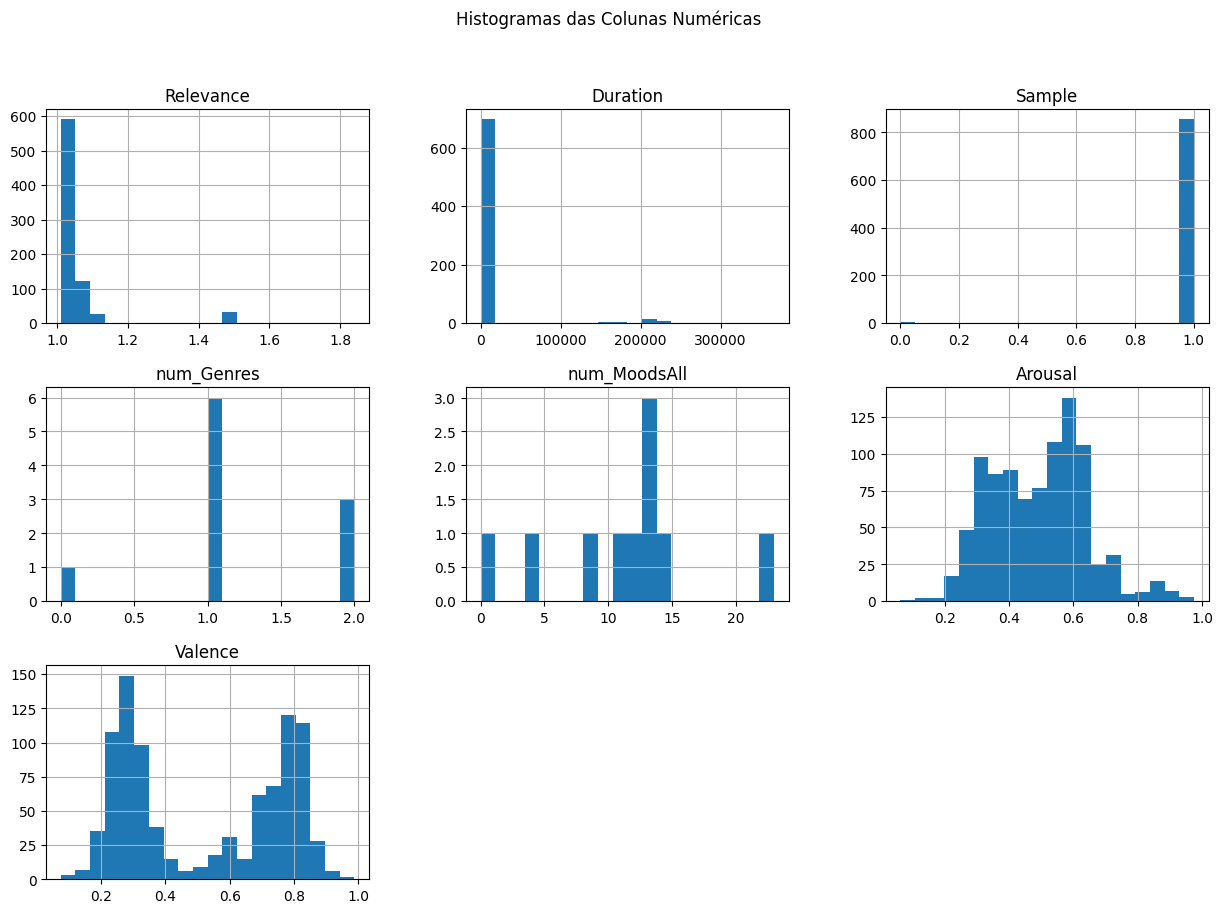

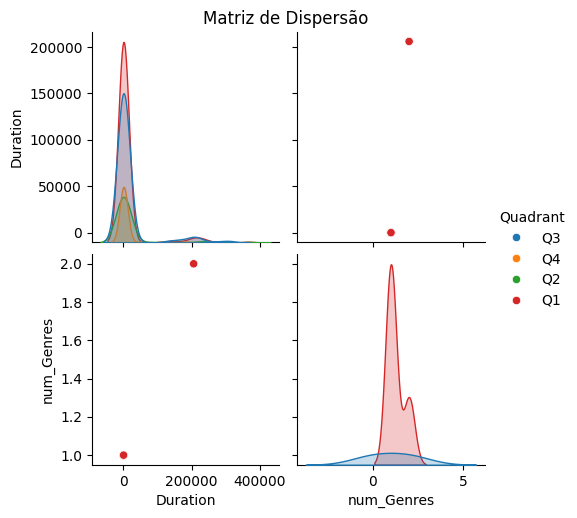


Análise de Artistas
Média de músicas por artista no treino: 1.42
Artista com mais músicas: Billie Holiday (17 músicas)
Artistas únicos no treino: 655
Artistas únicos no teste: 284
Músicas no Test Set que partilham artista com o Train Set: 204


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
import numpy as np

resume_df = pd.DataFrame({
    'Type': df_train.dtypes,
    'Missing (%)': df_train.isnull().mean() * 100,
    'Unique Values': df_train.nunique()
})
print("Resumo das Colunas")
print(resume_df.sort_values(by='Missing (%)', ascending=False))

numeric_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
df_train[numeric_cols].hist(bins=20, figsize=(15, 10))
plt.suptitle("Histogramas das Colunas Numéricas")
plt.show()

cols_for_pairplot = ['Duration', 'Year', 'num_Genres', 'Quadrant'] 
if all(col in df_train.columns for col in cols_for_pairplot):
    sns.pairplot(df_train[cols_for_pairplot], hue='Quadrant')
    plt.suptitle("Matriz de Dispersão", y=1.02)
    plt.show()

print("\nAnálise de Artistas")
artist_counts = df_train['Artist'].value_counts()
print(f"Média de músicas por artista no treino: {artist_counts.mean():.2f}")
print(f"Artista com mais músicas: {artist_counts.index[0]} ({artist_counts.iloc[0]} músicas)")

train_artists = set(df_train['Artist'].dropna())
test_artists = set(df_test['Artist'].dropna())
shared_artists = train_artists.intersection(test_artists)

print(f"Artistas únicos no treino: {len(train_artists)}")
print(f"Artistas únicos no teste: {len(test_artists)}")
print(f"Músicas no Test Set que partilham artista com o Train Set: {df_test['Artist'].isin(shared_artists).sum()}")

Column Description
                             Type  Missing (%)  Unique Values
num_Genres                float64    98.927039              3
num_MoodsAll              float64    98.927039              8
LowestYear                 object    34.549356            371
ActualYear                 object    22.746781             69
Duration                  float64    20.386266            272
Relevance                 float64    17.167382            757
Themes                     object    16.201717            628
ThemeWeights               object    16.201717            252
Genres                     object    13.519313            116
Year                       object    12.446352            487
AppearancesAlbumIDs        object    11.695279            780
AppearancesTrackIDs        object    11.695279            807
StyleWeights               object     8.798283            265
Styles                     object     8.798283            582
SampleURL                  object     8.369099            838
Moods                      object     7.832618            731
Sample                    float64     7.832618              2
MoodsAllWeights            object     2.575107            617
GenreWeights               object     2.360515             88
MoodsAll                   object     2.253219            809
AllMusic Extraction Date   object     0.000000              2
Title                      object     0.000000            898
Artist                     object     0.000000            655
AllMusic Id                object     0.000000            911
Audio_Song                 object     0.000000            914
Lyric_Song                 object     0.000000            914
Quadrant                   object     0.000000              4
Arousal                   float64     0.000000            269
Valence                   float64     0.000000            305

The columns num_Genres and num_MoodsAll are pratically empty, becoming unusable

THe columns AllMusic Extraction Date and Sample show nearly constant results, with AllMusic Extraction being the date of download and Sample being a binary flag indicating the existance of a sample.

The Relevance column represents the score returned by AllMusic for the query that retrieved the track, so doesn't measure any intrinsic musical measuserement. Similarly the Sample column is merely a binary flag rather than the audio data itself

In the training set, there are 655 unique artists. The number of songs per artist ranges from 1 up to a maximum of 17 (Billie Holiday), with an average of 1.42 songs per artist.

Crucially, when comparing the partitions, 204 songs in the test set share an artist with the training data. This means that approximately 50% of the test partition (204 out of 409 songs) is not truly independent from the training set in terms of authorship. In music emotion recognition, if a model learns an artist's specific acoustic signature or voice rather than general emotional features, its performance will be artificially inflated on these overlapping artists.